In [1]:
import pandas as pd

comparison = pd.DataFrame({
    "Metric": ["AUC", "Gini", "KS"],
    "Champion": [0.5969, 0.1938, 0.1455],
    "Challenger": [0.5962, 0.1925, 0.1413]
})

comparison

,Metric,Champion,Challenger
0,AUC,0.5969,0.5962
1,Gini,0.1938,0.1925
2,KS,0.1455,0.1413


In [2]:
comparison["Champion_Better"] = (
    comparison["Champion"] > comparison["Challenger"]
)

comparison

,Metric,Champion,Challenger,Champion_Better
0,AUC,0.5969,0.5962,True
1,Gini,0.1938,0.1925,True
2,KS,0.1455,0.1413,True


In [3]:
comparison.to_csv(
    "../outputs/metrics/champion_vs_challenger.csv",
    index=False
)

print("Champion vs Challenger comparison saved.")

Champion vs Challenger comparison saved.


In [1]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report
)
import numpy as np
import pandas as pd

In [2]:
train_df = pd.read_csv("../data/processed/train_data.csv")
test_df = pd.read_csv("../data/processed/test_data.csv")

X_train = train_df.drop(columns=["Bad"])
y_train = train_df["Bad"]

X_test = test_df.drop(columns=["Bad"])
y_test = test_df["Bad"]

In [3]:
X_train = X_train.drop(columns=["Customer_ID"], errors="ignore")
X_test = X_test.drop(columns=["Customer_ID"], errors="ignore")

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Identify categorical and numerical columns
categorical_cols = X_train.select_dtypes(include=["object"]).columns
numeric_cols = X_train.select_dtypes(exclude=["object"]).columns

print("Categorical columns:")
print(list(categorical_cols))

print("\nNumerical columns:")
print(list(numeric_cols))

Categorical columns:
['Employment_Type', 'Home_Ownership', 'Loan_Purpose', 'State']

Numerical columns:
['Age', 'Monthly_Income', 'Employment_Length_Years', 'Years_at_Address', 'Number_of_Dependents', 'Credit_Utilization', 'Number_of_Credit_Lines', 'Number_of_Open_Loans', 'Number_of_Delinquencies_30', 'Number_of_Delinquencies_60', 'Number_of_Delinquencies_90', 'Total_Debt', 'Debt_to_Income', 'Credit_History_Years', 'Recent_Inquiries_6M', 'Loan_Amount', 'Loan_Tenure_Months', 'Interest_Rate', 'Income_Missing', 'DTI_Missing', 'Employment_Length_Missing']


C:\Users\HP\AppData\Local\Temp\ipykernel_22652\2049351593.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X_train.select_dtypes(include=["object"]).columns


In [8]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_cols),
        ("cat", categorical_transformer, categorical_cols)
    ]
)

In [9]:
rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=300,
            max_depth=8,
            min_samples_leaf=50,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

rf_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](25,)","['Age','Monthly_Income','Employment_Length_Years',...,'Income_Missing', 'DTI_Missing','Employment_Length_Missing']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,25
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By s

In [10]:
rf_train_pd = rf_model.predict_proba(X_train)[:, 1]
rf_test_pd = rf_model.predict_proba(X_test)[:, 1]

rf_train_auc = roc_auc_score(y_train, rf_train_pd)
rf_test_auc = roc_auc_score(y_test, rf_test_pd)

print("Random Forest Train AUC:", rf_train_auc)
print("Random Forest Test AUC:", rf_test_auc)

Random Forest Train AUC: 0.6854358500103034
Random Forest Test AUC: 0.5950679372456986


In [11]:
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    brier_score_loss
)

# Gini
rf_gini = 2 * rf_test_auc - 1

# KS
fpr, tpr, thresholds = roc_curve(y_test, rf_test_pd)
rf_ks = max(tpr - fpr)

# Brier Score
rf_brier = brier_score_loss(y_test, rf_test_pd)

print("Random Forest Test AUC :", round(rf_test_auc, 4))
print("Random Forest Gini    :", round(rf_gini, 4))
print("Random Forest KS      :", round(rf_ks, 4))
print("Random Forest Brier   :", round(rf_brier, 4))

Random Forest Test AUC : 0.5951
Random Forest Gini    : 0.1901
Random Forest KS      : 0.1375
Random Forest Brier   : 0.2355


In [12]:
rf_model_fitted = rf_model.named_steps["model"]

feature_names = rf_model.named_steps[
    "preprocessor"
].get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model_fitted.feature_importances_
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

importance_df.head(15)

,Feature,Importance
13,num__Credit_History_Years,0.121598
5,num__Credit_Utilization,0.118079
0,num__Age,0.115656
12,num__Debt_to_Income,0.097459
17,num__Interest_Rate,0.081931
2,num__Employment_Length_Years,0.079371
1,num__Monthly_Income,0.055757
11,num__Total_Debt,0.046924
15,num__Loan_Amount,0.042342
3,num__Years_at_Address,0.033509


In [15]:
from xgboost import XGBClassifier

In [16]:
xgb_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", XGBClassifier(
            n_estimators=300,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

In [17]:
xgb_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](25,)","['Age','Monthly_Income','Employment_Length_Years',...,'Income_Missing', 'DTI_Missing','Employment_Length_Missing']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,25
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By s

In [18]:
xgb_train_pd = xgb_model.predict_proba(X_train)[:, 1]
xgb_test_pd = xgb_model.predict_proba(X_test)[:, 1]

In [19]:
xgb_train_auc = roc_auc_score(y_train, xgb_train_pd)
xgb_test_auc = roc_auc_score(y_test, xgb_test_pd)

print("XGBoost Train AUC:", xgb_train_auc)
print("XGBoost Test AUC :", xgb_test_auc)

XGBoost Train AUC: 0.7282835323999284
XGBoost Test AUC : 0.5859712769660413


In [20]:
xgb_gini = 2 * xgb_test_auc - 1

fpr, tpr, thresholds = roc_curve(y_test, xgb_test_pd)
xgb_ks = max(tpr - fpr)

xgb_brier = brier_score_loss(
    y_test,
    xgb_test_pd
)

print("XGBoost Test AUC :", round(xgb_test_auc, 4))
print("XGBoost Gini     :", round(xgb_gini, 4))
print("XGBoost KS       :", round(xgb_ks, 4))
print("XGBoost Brier    :", round(xgb_brier, 4))

XGBoost Test AUC : 0.586
XGBoost Gini     : 0.1719
XGBoost KS       : 0.128
XGBoost Brier    : 0.0633


In [21]:
comparison_all = pd.DataFrame({
    "Metric": [
        "AUC",
        "Gini",
        "KS",
        "Brier Score",
        "Train AUC",
        "Test AUC"
    ],

    "WOE Logistic Regression": [
        0.5969,
        0.1938,
        0.1455,
        0.0630,
        0.5987,
        0.5969
    ],

    "Random Forest": [
        rf_test_auc,
        rf_gini,
        rf_ks,
        rf_brier,
        rf_train_auc,
        rf_test_auc
    ],

    "XGBoost": [
        xgb_test_auc,
        xgb_gini,
        xgb_ks,
        xgb_brier,
        xgb_train_auc,
        xgb_test_auc
    ]
})

comparison_all

,Metric,WOE Logistic Regression,Random Forest,XGBoost
0,AUC,0.5969,0.595068,0.585971
1,Gini,0.1938,0.190136,0.171943
2,KS,0.1455,0.137516,0.128036
3,Brier Score,0.0630,0.235483,0.063256
4,Train AUC,0.5987,0.685436,0.728284
5,Test AUC,0.5969,0.595068,0.585971


In [22]:
comparison_all = comparison_all.round(4)

comparison_all

,Metric,WOE Logistic Regression,Random Forest,XGBoost
0,AUC,0.5969,0.5951,0.5860
1,Gini,0.1938,0.1901,0.1719
2,KS,0.1455,0.1375,0.1280
3,Brier Score,0.0630,0.2355,0.0633
4,Train AUC,0.5987,0.6854,0.7283
5,Test AUC,0.5969,0.5951,0.5860


In [23]:
comparison_gap = pd.DataFrame({
    "Model": [
        "WOE Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],

    "Train AUC": [
        0.5987,
        rf_train_auc,
        xgb_train_auc
    ],

    "Test AUC": [
        0.5969,
        rf_test_auc,
        xgb_test_auc
    ]
})

comparison_gap["AUC_Gap"] = (
    comparison_gap["Train AUC"]
    - comparison_gap["Test AUC"]
)

comparison_gap.round(4)

,Model,Train AUC,Test AUC,AUC_Gap
0,WOE Logistic Regression,0.5987,0.5969,0.0018
1,Random Forest,0.6854,0.5951,0.0904
2,XGBoost,0.7283,0.5860,0.1423


In [24]:
comparison_all.to_csv(
    "../outputs/metrics/final_model_comparison.csv",
    index=False
)

comparison_gap.to_csv(
    "../outputs/metrics/model_overfitting_comparison.csv",
    index=False
)

print("Final model comparison saved.")

Final model comparison saved.


In [26]:
import shap
import matplotlib.pyplot as plt

In [27]:
X_test_transformed = xgb_model.named_steps[
    "preprocessor"
].transform(X_test)

In [28]:
xgb_fitted = xgb_model.named_steps["model"]

In [29]:
explainer = shap.TreeExplainer(xgb_fitted)

In [30]:
shap_values = explainer.shap_values(X_test_transformed)

In [31]:
print("Test data shape:", X_test_transformed.shape)
print("SHAP shape:", shap_values.shape)

Test data shape: (30000, 46)
SHAP shape: (30000, 46)


In [33]:
shap_importance = pd.DataFrame({
    "Feature": xgb_model
        .named_steps["preprocessor"]
        .get_feature_names_out(),
    "Mean_Absolute_SHAP": np.abs(shap_values).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
)

shap_importance.to_csv(
    "../outputs/metrics/xgboost_shap_importance.csv",
    index=False
)

shap_importance.head(20)

,Feature,Mean_Absolute_SHAP
13,num__Credit_History_Years,0.124524
2,num__Employment_Length_Years,0.106869
5,num__Credit_Utilization,0.105824
14,num__Recent_Inquiries_6M,0.063847
0,num__Age,0.059052
11,num__Total_Debt,0.057842
12,num__Debt_to_Income,0.053666
1,num__Monthly_Income,0.050569
17,num__Interest_Rate,0.038305
3,num__Years_at_Address,0.036582


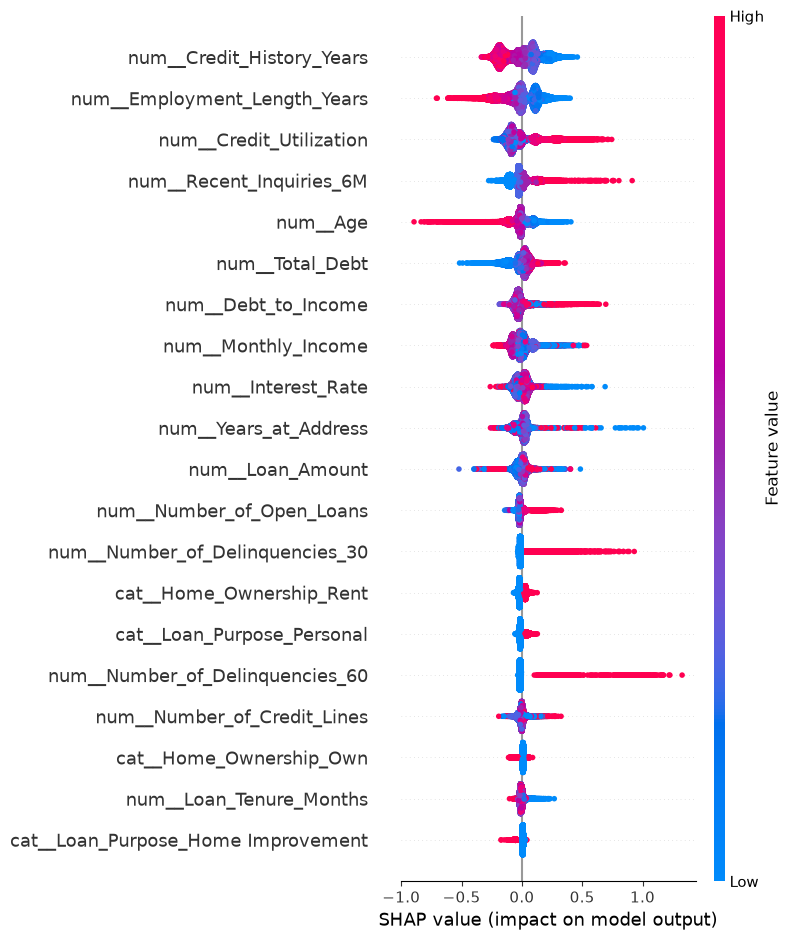

In [35]:
plt.figure()

shap.summary_plot(
    shap_values,
    X_test_transformed,
    feature_names=feature_names,
    show=False
)

plt.tight_layout()

plt.savefig(
    "../outputs/figures/xgboost_shap_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()

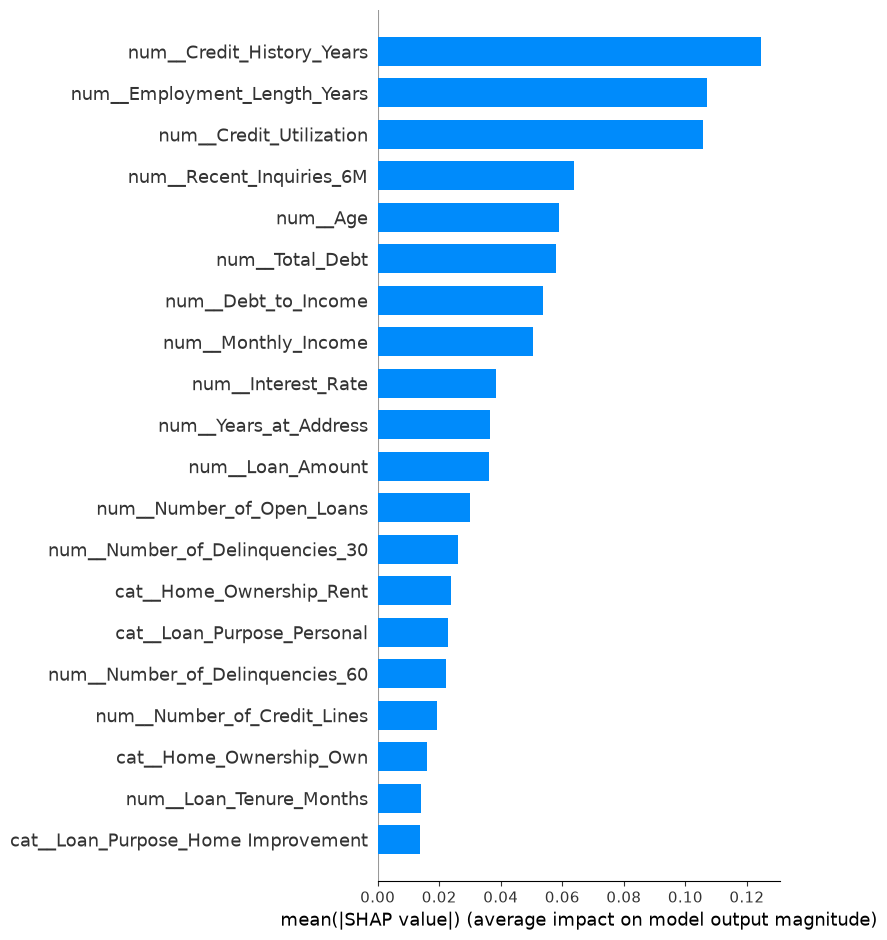

In [36]:
plt.figure()

shap.summary_plot(
    shap_values,
    X_test_transformed,
    feature_names=feature_names,
    plot_type="bar",
    show=False
)

plt.tight_layout()

plt.savefig(
    "../outputs/figures/xgboost_shap_importance_bar.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()

In [37]:
# ============================================
# FINAL MODEL COMPARISON
# ============================================

comparison_all = pd.DataFrame({
    "Metric": [
        "AUC",
        "Gini",
        "KS",
        "Brier Score",
        "Train AUC",
        "Test AUC"
    ],

    "WOE Logistic Regression": [
        0.5969,
        0.1938,
        0.1455,
        0.0630,
        0.5987,
        0.5969
    ],

    "Random Forest": [
        rf_test_auc,
        rf_gini,
        rf_ks,
        rf_brier,
        rf_train_auc,
        rf_test_auc
    ],

    "XGBoost": [
        xgb_test_auc,
        xgb_gini,
        xgb_ks,
        xgb_brier,
        xgb_train_auc,
        xgb_test_auc
    ]
})

comparison_all = comparison_all.round(4)

comparison_all

,Metric,WOE Logistic Regression,Random Forest,XGBoost
0,AUC,0.5969,0.5951,0.5860
1,Gini,0.1938,0.1901,0.1719
2,KS,0.1455,0.1375,0.1280
3,Brier Score,0.0630,0.2355,0.0633
4,Train AUC,0.5987,0.6854,0.7283
5,Test AUC,0.5969,0.5951,0.5860
